# EDA Home Credit Default Risk

Исследуются данные кредитных заявок и связанных историй. Цель - выявить особенности качества данных и ограничения, существенные для конфигурации AutoML-пайплайна. `TARGET=1` соответствует проблемам с погашением кредита.

Источник: [Home Credit Default Risk (Kaggle)](https://www.kaggle.com/competitions/home-credit-default-risk/data). Расчёты и выводы представлены в `EDA_home_credit_default_risk.md`.

Архивы [application_test.zip](https://drive.google.com/file/d/15Gc1L5xE3Cc0UWvAfdLlMhxQ5FG5-8l7/view?usp=drive_link), [application_train.zip](https://drive.google.com/file/d/1c3C49iid65SHgBw7XafRS3c3wagrGlD9/view?usp=drive_link), [bureau.zip](https://drive.google.com/file/d/1tA9bU0DfTzO9myXD3zRyzzN8Q_Vf0JdY/view?usp=drive_link), [bureau_balance.zip](https://drive.google.com/file/d/1I9n_WlIvBC_xkqic-QiyUQystmpdTVFw/view?usp=drive_link), [credit_card_balance.zip](https://drive.google.com/file/d/1IjM6egMexJ8YMNFeHeZ1OJzeIudjbHin/view?usp=drive_link), [HomeCredit_columns_description.zip](https://drive.google.com/file/d/14t7-SPGv0pTrYbzilwKmgnOo948h9m1b/view?usp=drive_link), [installments_payments.zip](https://drive.google.com/file/d/1_iNGR1I6drzPcmHcqoSV-NtbN_3TbpUC/view?usp=drive_link), [POS_CASH_balance.zip](https://drive.google.com/file/d/1xEezOEpUSRLe4tT3M3V0BTnfBrNyzkUW/view?usp=drive_link), [previous_application.zip](https://drive.google.com/file/d/1nxFIDgPLiQMmsvjTG9M0yqqVVB5ZMm9g/view?usp=drive_link) размещаются рядом с ноутбуком. Ячейки выполняются последовательно.

## 1. Первичный анализ

Проверяются состав таблиц, структура основной обучающей выборки, типы признаков и уникальность идентификаторов.

In [9]:
from pathlib import Path
from collections import Counter
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

names = ["application_train", "application_test", "bureau", "bureau_balance",
         "previous_application", "POS_CASH_balance", "credit_card_balance",
         "installments_payments", "HomeCredit_columns_description"]

base = Path(".")

files = {name: base / f"{name}.zip" for name in names}

missing_files = [str(p) for p in files.values() if not p.exists()]
assert not missing_files, f"Не найдены архивы: {missing_files}"


In [10]:
train = pd.read_csv(files["application_train"], low_memory=False)
test = pd.read_csv(files["application_test"], low_memory=False)
print("Train:", train.shape, "Test:", test.shape)
print("TARGET только в train:", "TARGET" in train and "TARGET" not in test)
print("Признаки совпадают:", set(train.columns) - {"TARGET"} == set(test.columns))
print("Числовых столбцов в train:", len(train.select_dtypes(include="number").columns))
print("Прочих столбцов в train:", len(train.select_dtypes(exclude="number").columns))
display(train.head(3))

Train: (307511, 122) Test: (48744, 121)
TARGET только в train: True
Признаки совпадают: True
Числовых столбцов в train: 106
Прочих столбцов в train: 16


,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0


In [11]:
print("Повторов SK_ID_CURR в train:", train["SK_ID_CURR"].duplicated().sum())
print("Повторов SK_ID_CURR в test:", test["SK_ID_CURR"].duplicated().sum())
print("Пересечений ключей train и test:", train["SK_ID_CURR"].isin(test["SK_ID_CURR"]).sum())
print("Полных дубликатов train:", train.duplicated().sum())
print("Пропусков TARGET:", train["TARGET"].isna().sum())

Повторов SK_ID_CURR в train: 0
Повторов SK_ID_CURR в test: 0
Пересечений ключей train и test: 0
Полных дубликатов train: 0
Пропусков TARGET: 0


## 2. Целевая переменная и дисбаланс классов

Целевой признак не следует подменять количеством кредита или просрочек в связанных таблицах.

,Количество,"Доля, %"
TARGET,,
0,282686,91.927
1,24825,8.073


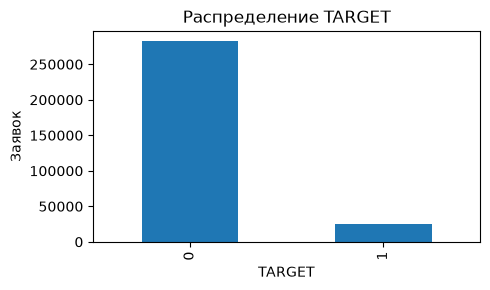

In [12]:
target_counts = train["TARGET"].value_counts(dropna=False).sort_index()
display(pd.DataFrame({"Количество": target_counts,
                      "Доля, %": (100 * target_counts / len(train)).round(3)}))
target_counts.plot.bar(figsize=(5, 3), title="Распределение TARGET")
plt.xlabel("TARGET")
plt.ylabel("Заявок")
plt.tight_layout()
plt.show()

## 3. Пропуски и различия train/test

Рассматриваются все признаки основной таблицы. Пропуски могут быть структурными или связанными с доступностью внешних данных.

In [13]:
missing_train = train.isna().mean().mul(100).sort_values(ascending=False)
missing_test = test.isna().mean().mul(100).sort_values(ascending=False)
print("Столбцов с пропусками в train:", int((missing_train > 0).sum()))
print("Столбцов с >=50% пропусков в train:", int((missing_train >= 50).sum()))
print("Полностью пустых в train:", int((missing_train == 100).sum()))
display(missing_train.head(15).round(2).to_frame("Пропуски в train, %"))

Столбцов с пропусками в train: 67
Столбцов с >=50% пропусков в train: 41
Полностью пустых в train: 0


,"Пропуски в train, %"
COMMONAREA_AVG,69.87
COMMONAREA_MODE,69.87
COMMONAREA_MEDI,69.87
NONLIVINGAPARTMENTS_MEDI,69.43
NONLIVINGAPARTMENTS_MODE,69.43
NONLIVINGAPARTMENTS_AVG,69.43
FONDKAPREMONT_MODE,68.39
LIVINGAPARTMENTS_AVG,68.35
LIVINGAPARTMENTS_MEDI,68.35
LIVINGAPARTMENTS_MODE,68.35


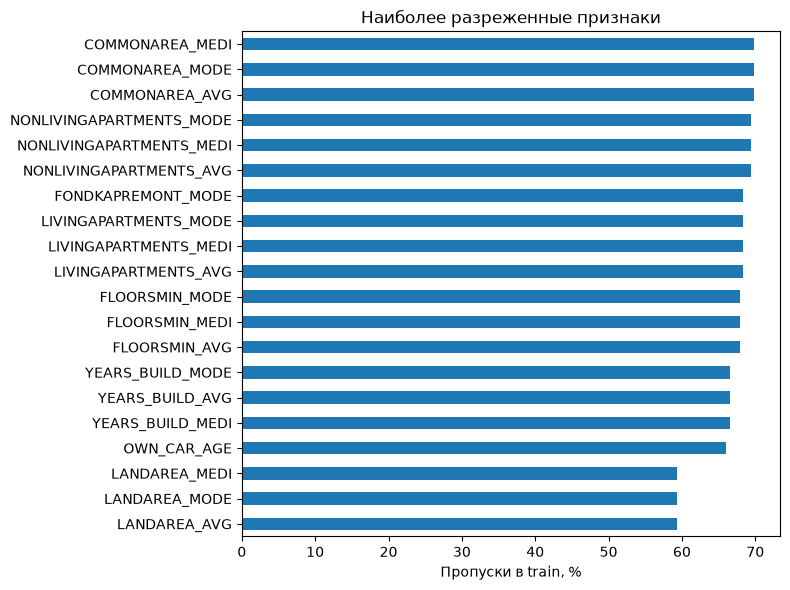

In [14]:
missing_train.head(20).sort_values().plot.barh(figsize=(8, 6))
plt.xlabel("Пропуски в train, %")
plt.title("Наиболее разреженные признаки")
plt.tight_layout()
plt.show()

In [15]:
shared = [c for c in test.columns if c in train.columns]
missing_diff = (missing_test[shared] - missing_train[shared]).sort_values(key=abs, ascending=False)
drift_missing = pd.DataFrame({"train, %": missing_train[shared],
                              "test, %": missing_test[shared],
                              "Разница, п.п.": missing_test[shared] - missing_train[shared]})
display(drift_missing.loc[missing_diff.head(12).index].round(2))
print("Максимальная разница пропусков, п.п.:", round(missing_diff.abs().max(), 2))

,"train, %","test, %","Разница, п.п."
EXT_SOURCE_1,56.38,42.12,-14.26
EXT_SOURCE_3,19.83,17.78,-2.04
ENTRANCES_AVG,50.35,48.37,-1.98
ENTRANCES_MEDI,50.35,48.37,-1.98
ENTRANCES_MODE,50.35,48.37,-1.98
FLOORSMAX_MODE,49.76,47.84,-1.92
FLOORSMAX_MEDI,49.76,47.84,-1.92
FLOORSMAX_AVG,49.76,47.84,-1.92
YEARS_BEGINEXPLUATATION_AVG,48.78,46.89,-1.89
YEARS_BEGINEXPLUATATION_MEDI,48.78,46.89,-1.89


Максимальная разница пропусков, п.п.: 14.26


## 4. Специальные значения и аномалии

Некоторые специальные коды нельзя трактовать как реальные даты, сроки трудоустройства или обычные категории.

In [16]:
sentinel = train["DAYS_EMPLOYED"].eq(365243)
print("DAYS_EMPLOYED=365243:", int(sentinel.sum()),
      f"({100 * sentinel.mean():.2f}%)")
print("ORGANIZATION_TYPE=XNA при таком коде:",
      int(train.loc[sentinel, "ORGANIZATION_TYPE"].eq("XNA").sum()))
for col, value in [("CODE_GENDER", "XNA"), ("NAME_FAMILY_STATUS", "Unknown")]:
    print(f"{col}={value}:", int(train[col].eq(value).sum()))
print("DAYS_EMPLOYED: минимум / максимум:", train["DAYS_EMPLOYED"].min(),
      train["DAYS_EMPLOYED"].max())

DAYS_EMPLOYED=365243: 55374 (18.01%)
ORGANIZATION_TYPE=XNA при таком коде: 55374
CODE_GENDER=XNA: 4
NAME_FAMILY_STATUS=Unknown: 2
DAYS_EMPLOYED: минимум / максимум: -17912 365243


AMT_INCOME_TOTAL медиана: 147150.0 p99: 472500.0 максимум: 117000000.0
AMT_CREDIT медиана: 513531.0 p99: 1854000.0 максимум: 4050000.0
AMT_ANNUITY медиана: 24903.0 p99: 70006.5 максимум: 258025.5


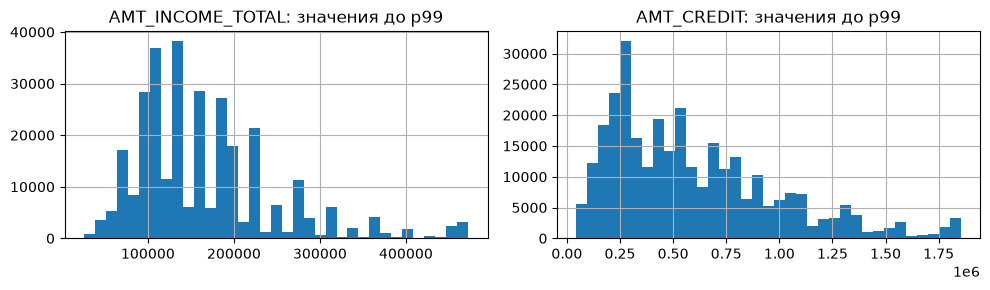

In [17]:
for col in ["AMT_INCOME_TOTAL", "AMT_CREDIT", "AMT_ANNUITY"]:
    x = train[col].dropna()
    print(col, "медиана:", round(x.median(), 2),
          "p99:", round(x.quantile(.99), 2),
          "максимум:", round(x.max(), 2))

fig, axes = plt.subplots(1, 2, figsize=(10, 3))
for ax, col in zip(axes, ["AMT_INCOME_TOTAL", "AMT_CREDIT"]):
    x = train[col].dropna()
    x.clip(upper=x.quantile(.99)).hist(bins=35, ax=ax)
    ax.set_title(f"{col}: значения до p99")
plt.tight_layout()
plt.show()

In [18]:
for col in ["DAYS_BIRTH", "DAYS_EMPLOYED", "DAYS_REGISTRATION", "DAYS_ID_PUBLISH"]:
    x = train[col]
    print(col, "положительных:", int((x > 0).sum()),
          "нулевых:", int((x == 0).sum()),
          "отрицательных:", int((x < 0).sum()))

DAYS_BIRTH положительных: 0 нулевых: 0 отрицательных: 307511
DAYS_EMPLOYED положительных: 55374 нулевых: 2 отрицательных: 252135
DAYS_REGISTRATION положительных: 0 нулевых: 80 отрицательных: 307431
DAYS_ID_PUBLISH положительных: 0 нулевых: 16 отрицательных: 307495


## 5. Категориальные и числовые зависимости

Различия долей `TARGET=1` показывают ассоциации в данных и сами по себе не доказывают причинных связей.

In [19]:
categories = ["NAME_CONTRACT_TYPE", "CODE_GENDER", "NAME_INCOME_TYPE",
              "NAME_EDUCATION_TYPE", "NAME_FAMILY_STATUS"]
for col in categories:
    table = train.groupby(col, dropna=False)["TARGET"].agg(["size", "mean"])
    table.columns = ["Заявок", "Доля TARGET=1"]
    table["Доля TARGET=1"] *= 100
    print()
    print(col)
    display(table.sort_values("Заявок", ascending=False).head(10).round(2))


NAME_CONTRACT_TYPE


,Заявок,Доля TARGET=1
NAME_CONTRACT_TYPE,,
Cash loans,278232,8.35
Revolving loans,29279,5.48



CODE_GENDER


,Заявок,Доля TARGET=1
CODE_GENDER,,
F,202448,7.00
M,105059,10.14
XNA,4,0.00



NAME_INCOME_TYPE


,Заявок,Доля TARGET=1
NAME_INCOME_TYPE,,
Working,158774,9.59
Commercial associate,71617,7.48
Pensioner,55362,5.39
State servant,21703,5.75
Unemployed,22,36.36
Student,18,0.00
Businessman,10,0.00
Maternity leave,5,40.00



NAME_EDUCATION_TYPE


,Заявок,Доля TARGET=1
NAME_EDUCATION_TYPE,,
Secondary / secondary special,218391,8.94
Higher education,74863,5.36
Incomplete higher,10277,8.48
Lower secondary,3816,10.93
Academic degree,164,1.83



NAME_FAMILY_STATUS


,Заявок,Доля TARGET=1
NAME_FAMILY_STATUS,,
Married,196432,7.56
Single / not married,45444,9.81
Civil marriage,29775,9.94
Separated,19770,8.19
Widow,16088,5.82
Unknown,2,0.00


In [20]:
for col in ["EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3"]:
    sub = train[[col, "TARGET"]].dropna()
    print(col, "доступно:", len(sub),
          "корреляция с TARGET:", round(sub[col].corr(sub["TARGET"]), 3))
    groups = pd.qcut(sub[col], 5, duplicates="drop")
    display((100 * sub.groupby(groups, observed=True)["TARGET"].mean())
            .round(2).to_frame("Доля TARGET=1, %"))

EXT_SOURCE_1 доступно: 134133 корреляция с TARGET: -0.155


,"Доля TARGET=1, %"
EXT_SOURCE_1,
"(0.013600000000000001, 0.296]",14.58
"(0.296, 0.438]",8.74
"(0.438, 0.573]",6.36
"(0.573, 0.71]",4.76
"(0.71, 0.963]",3.04


EXT_SOURCE_2 доступно: 306851 корреляция с TARGET: -0.16


,"Доля TARGET=1, %"
EXT_SOURCE_2,
"(-0.0009999183, 0.34]",15.21
"(0.34, 0.512]",9.16
"(0.512, 0.608]",7.04
"(0.608, 0.682]",5.37
"(0.682, 0.855]",3.59


EXT_SOURCE_3 доступно: 246546 корреляция с TARGET: -0.179


,"Доля TARGET=1, %"
EXT_SOURCE_3,
"(-0.000473, 0.33]",16.38
"(0.33, 0.476]",8.75
"(0.476, 0.592]",5.75
"(0.592, 0.694]",4.48
"(0.694, 0.896]",3.38


In [21]:
numeric_cols = [c for c in train.select_dtypes(include="number")
                if c not in ["TARGET", "SK_ID_CURR"]]
correlations = train[numeric_cols].corrwith(train["TARGET"]).dropna()
print("Корреляции с TARGET, наибольшие по модулю:")
display(correlations.reindex(correlations.abs().nlargest(15).index)
        .round(3).to_frame("Корреляция"))

Корреляции с TARGET, наибольшие по модулю:


,Корреляция
EXT_SOURCE_3,-0.179
EXT_SOURCE_2,-0.160
EXT_SOURCE_1,-0.155
DAYS_BIRTH,0.078
REGION_RATING_CLIENT_W_CITY,0.061
REGION_RATING_CLIENT,0.059
DAYS_LAST_PHONE_CHANGE,0.055
DAYS_ID_PUBLISH,0.051
REG_CITY_NOT_WORK_CITY,0.051
FLAG_EMP_PHONE,0.046


In [22]:
for col in ["AMT_CREDIT", "AMT_INCOME_TOTAL", "DAYS_BIRTH"]:
    sub = train[[col, "TARGET"]].dropna()
    buckets = pd.qcut(sub[col], 5, duplicates="drop")
    by_bucket = sub.groupby(buckets, observed=True)["TARGET"].agg(["size", "mean"])
    by_bucket.columns = ["Заявок", "Доля TARGET=1"]
    by_bucket["Доля TARGET=1"] *= 100
    print()
    print(col)
    display(by_bucket.round(2))


AMT_CREDIT


,Заявок,Доля TARGET=1
AMT_CREDIT,,
"(44999.999, 254700.0]",64925,7.24
"(254700.0, 432000.0]",58098,9.17
"(432000.0, 604152.0]",61552,10.05
"(604152.0, 900000.0]",64024,7.85
"(900000.0, 4050000.0]",58912,6.08



AMT_INCOME_TOTAL


,Заявок,Доля TARGET=1
AMT_INCOME_TOTAL,,
"(25649.999, 99000.0]",63671,8.21
"(99000.0, 135000.0]",85756,8.59
"(135000.0, 162000.0]",35453,8.68
"(162000.0, 225000.0]",75513,8.06
"(225000.0, 117000000.0]",47118,6.52



DAYS_BIRTH


,Заявок,Доля TARGET=1
DAYS_BIRTH,,
"(-25229.001, -20474.0]",61513,5.16
"(-20474.0, -17220.0]",61498,6.74
"(-17220.0, -14416.0]",61517,7.85
"(-14416.0, -11694.0]",61495,9.33
"(-11694.0, -7489.0]",61488,11.28


## 6. Дополнительные таблицы и ключи

Одна заявка может иметь много записей в кредитных историях. Для использования в табличной модели требуется предварительное агрегирование, иначе прямой JOIN размножит строки.

In [23]:
schemas = {name: pd.read_csv(files[name], nrows=0,
                         encoding="latin1" if name == "HomeCredit_columns_description" else "utf-8").columns.tolist()
           for name in names if name not in ["application_train", "application_test"]}
for name, cols in schemas.items():
    print(name, "столбцов:", len(cols),
          "SK_ID_CURR:", "SK_ID_CURR" in cols,
          "SK_ID_PREV:", "SK_ID_PREV" in cols,
          "SK_ID_BUREAU:", "SK_ID_BUREAU" in cols)

bureau столбцов: 17 SK_ID_CURR: True SK_ID_PREV: False SK_ID_BUREAU: True
bureau_balance столбцов: 3 SK_ID_CURR: False SK_ID_PREV: False SK_ID_BUREAU: True
previous_application столбцов: 37 SK_ID_CURR: True SK_ID_PREV: True SK_ID_BUREAU: False
POS_CASH_balance столбцов: 8 SK_ID_CURR: True SK_ID_PREV: True SK_ID_BUREAU: False
credit_card_balance столбцов: 23 SK_ID_CURR: True SK_ID_PREV: True SK_ID_BUREAU: False
installments_payments столбцов: 8 SK_ID_CURR: True SK_ID_PREV: True SK_ID_BUREAU: False
HomeCredit_columns_description столбцов: 5 SK_ID_CURR: False SK_ID_PREV: False SK_ID_BUREAU: False


In [24]:
# Ключи родительских таблиц, необходимые для проверки связей.
bureau_keys = pd.Index(pd.read_csv(files["bureau"], usecols=["SK_ID_BUREAU"])["SK_ID_BUREAU"])
previous_keys = pd.Index(pd.read_csv(files["previous_application"],
                                     usecols=["SK_ID_PREV"])["SK_ID_PREV"])
print("Уникальных SK_ID_BUREAU:", len(bureau_keys))
print("Уникальных SK_ID_PREV:", len(previous_keys))

Уникальных SK_ID_BUREAU: 1716428
Уникальных SK_ID_PREV: 1670214


In [25]:
sources = ["bureau", "previous_application", "POS_CASH_balance",
           "credit_card_balance", "installments_payments"]
max_id = int(max(train["SK_ID_CURR"].max(), test["SK_ID_CURR"].max()))
history_counts = {}
source_rows = {}
orphans = {}
for name in sources:
    counts = np.zeros(max_id + 1, dtype=np.int64)
    orphan_keys = set()
    orphan_rows = 0
    columns_to_read = ["SK_ID_CURR"]
    if name in ["POS_CASH_balance", "credit_card_balance", "installments_payments"]:
        columns_to_read.append("SK_ID_PREV")
    rows = 0
    for part in pd.read_csv(files[name], usecols=columns_to_read, chunksize=250_000):
        rows += len(part)
        ids = part["SK_ID_CURR"].to_numpy(dtype="int64")
        assert ids.min() >= 0 and ids.max() <= max_id, "Найдены неожиданные SK_ID_CURR"
        counts += np.bincount(ids, minlength=max_id + 1)
        if "SK_ID_PREV" in part:
            unknown = previous_keys.get_indexer(part["SK_ID_PREV"]) < 0
            orphan_rows += int(unknown.sum())
            orphan_keys.update(part.loc[unknown, "SK_ID_PREV"].dropna().astype("int64"))
    history_counts[name] = counts
    source_rows[name] = rows
    if len(columns_to_read) == 2:
        orphans[name] = (len(orphan_keys), orphan_rows)
    print(name, "строк:", rows, "уникальных заявок:", int(np.count_nonzero(counts)))

bureau строк: 1716428 уникальных заявок: 305811
previous_application строк: 1670214 уникальных заявок: 338857
POS_CASH_balance строк: 10001358 уникальных заявок: 337252
credit_card_balance строк: 3840312 уникальных заявок: 103558
installments_payments строк: 13605401 уникальных заявок: 339587


In [26]:
coverage_rows = []
train_ids = train["SK_ID_CURR"].to_numpy(dtype="int64")
test_ids = test["SK_ID_CURR"].to_numpy(dtype="int64")
for name, counts in history_counts.items():
    has_train = counts[train_ids] > 0
    has_test = counts[test_ids] > 0
    coverage_rows.append({
        "Источник": name,
        "Строк": source_rows[name],
        "Макс. записей на заявку": int(counts.max()),
        "С историей train": int(has_train.sum()),
        "Охват train, %": round(100 * has_train.mean(), 2),
        "Охват test, %": round(100 * has_test.mean(), 2),
        "TARGET=1 с историей, %": round(100 * train.loc[has_train, "TARGET"].mean(), 2),
        "TARGET=1 без истории, %": round(100 * train.loc[~has_train, "TARGET"].mean(), 2)
    })
coverage = pd.DataFrame(coverage_rows).set_index("Источник")
display(coverage)

,Строк,Макс. записей на заявку,С историей train,"Охват train, %","Охват test, %","TARGET=1 с историей, %","TARGET=1 без истории, %"
Источник,,,,,,,
bureau,1716428,116,263491,85.69,86.82,7.73,10.12
previous_application,1670214,77,291057,94.65,98.06,8.19,5.96
POS_CASH_balance,10001358,295,289444,94.12,98.08,8.16,6.66
credit_card_balance,3840312,192,86905,28.26,34.16,8.67,7.84
installments_payments,13605401,372,291643,94.84,98.36,8.19,5.98


In [27]:
print("Несовпадающие SK_ID_PREV с previous_application:")
for name, (unique_keys, rows) in orphans.items():
    print(name, "уникальных SK_ID_PREV:", unique_keys, "строк:", rows)

Несовпадающие SK_ID_PREV с previous_application:
POS_CASH_balance уникальных SK_ID_PREV: 37422 строк: 340561
credit_card_balance уникальных SK_ID_PREV: 11372 строк: 1082816
installments_payments уникальных SK_ID_PREV: 38847 строк: 1250826


In [28]:
unknown_bureau_keys = set()
unknown_bureau_rows = 0
balance_rows = 0
for part in pd.read_csv(files["bureau_balance"],
                        usecols=["SK_ID_BUREAU"], chunksize=300_000):
    balance_rows += len(part)
    unmatched = bureau_keys.get_indexer(part["SK_ID_BUREAU"]) < 0
    unknown_bureau_rows += int(unmatched.sum())
    unknown_bureau_keys.update(part.loc[unmatched, "SK_ID_BUREAU"].astype("int64"))
print("bureau_balance строк:", balance_rows)
print("SK_ID_BUREAU без записи в bureau:", len(unknown_bureau_keys))
print("Строк с такими ключами:", unknown_bureau_rows,
      f"({100 * unknown_bureau_rows / balance_rows:.2f}%)")

bureau_balance строк: 27299925
SK_ID_BUREAU без записи в bureau: 43041
Строк с такими ключами: 3120184 (11.43%)


## 7. Исторические события и специальные коды

Проверяется наличие событий, которые потенциально могли появиться после момента подачи заявки. Наличие такого поля не является доказательством утечки без бизнес-контекста.

In [29]:
bureau_info = pd.read_csv(files["bureau"],
    usecols=["SK_ID_CURR", "DAYS_CREDIT", "DAYS_CREDIT_UPDATE", "DAYS_CREDIT_ENDDATE"])
print("DAYS_CREDIT_UPDATE > 0:", int((bureau_info["DAYS_CREDIT_UPDATE"] > 0).sum()))
print("Макс. DAYS_CREDIT_UPDATE:", bureau_info["DAYS_CREDIT_UPDATE"].max())
print("DAYS_CREDIT_ENDDATE > 0:", int((bureau_info["DAYS_CREDIT_ENDDATE"] > 0).sum()))
print("DAYS_CREDIT > 0:", int((bureau_info["DAYS_CREDIT"] > 0).sum()))

DAYS_CREDIT_UPDATE > 0: 17
Макс. DAYS_CREDIT_UPDATE: 372
DAYS_CREDIT_ENDDATE > 0: 602603
DAYS_CREDIT > 0: 0


In [30]:
previous_info = pd.read_csv(files["previous_application"],
    usecols=["SK_ID_CURR", "SK_ID_PREV", "DAYS_FIRST_DRAWING", "DAYS_TERMINATION"])
for col in ["DAYS_FIRST_DRAWING", "DAYS_TERMINATION"]:
    x = previous_info[col]
    print(col, "значений 365243:", int(x.eq(365243).sum()),
          "пропусков:", int(x.isna().sum()))

DAYS_FIRST_DRAWING значений 365243: 934444 пропусков: 673065
DAYS_TERMINATION значений 365243: 225913 пропусков: 673065


In [31]:
for name in ["POS_CASH_balance", "credit_card_balance"]:
    n_future = 0
    n_rows = 0
    for part in pd.read_csv(files[name], usecols=["MONTHS_BALANCE"],
                            chunksize=300_000):
        n_rows += len(part)
        n_future += int(part["MONTHS_BALANCE"].gt(0).sum())
    print(name, "MONTHS_BALANCE > 0:", n_future, "из", n_rows)

POS_CASH_balance MONTHS_BALANCE > 0: 0 из 10001358
credit_card_balance MONTHS_BALANCE > 0: 0 из 3840312


## 8. Различия train/test по значениям

Сопоставление пропусков недостаточно для исключения сдвигов: дополнительно рассматриваются распределения и категориальный состав.

In [32]:
for col in ["EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3", "AMT_CREDIT", "AMT_INCOME_TOTAL"]:
    print(col, "train медиана:", round(train[col].median(), 3),
          "test медиана:", round(test[col].median(), 3),
          "пропуски train/test:", f"{train[col].isna().mean():.2%}",
          f"{test[col].isna().mean():.2%}")

EXT_SOURCE_1 train медиана: 0.506 test медиана: 0.507 пропуски train/test: 56.38% 42.12%
EXT_SOURCE_2 train медиана: 0.566 test медиана: 0.559 пропуски train/test: 0.21% 0.02%
EXT_SOURCE_3 train медиана: 0.535 test медиана: 0.519 пропуски train/test: 19.83% 17.78%
AMT_CREDIT train медиана: 513531.0 test медиана: 450000.0 пропуски train/test: 0.00% 0.00%
AMT_INCOME_TOTAL train медиана: 147150.0 test медиана: 157500.0 пропуски train/test: 0.00% 0.00%


In [33]:
cat_cols = [c for c in train.select_dtypes(exclude="number").columns
            if c in test.columns]
cat_shift = []
for col in cat_cols:
    train_vals = set(train[col].dropna().astype(str))
    test_vals = set(test[col].dropna().astype(str))
    cat_shift.append((col, len(test_vals - train_vals), len(train_vals - test_vals)))
cat_shift = pd.DataFrame(cat_shift, columns=["Признак", "Только в test", "Только в train"])
print("Категориальных признаков с новыми значениями в test:",
      int((cat_shift["Только в test"] > 0).sum()))
display(cat_shift.sort_values(["Только в test", "Только в train"],
                              ascending=False).head(12))

Категориальных признаков с новыми значениями в test: 0


,Признак,Только в test,Только в train
1,CODE_GENDER,0,1
5,NAME_INCOME_TYPE,0,1
7,NAME_FAMILY_STATUS,0,1
0,NAME_CONTRACT_TYPE,0,0
2,FLAG_OWN_CAR,0,0
3,FLAG_OWN_REALTY,0,0
4,NAME_TYPE_SUITE,0,0
6,NAME_EDUCATION_TYPE,0,0
8,NAME_HOUSING_TYPE,0,0
9,OCCUPATION_TYPE,0,0


## 9. Проверка предпосылок валидации

Абсолютной даты подачи текущей заявки в основной таблице нет. Поэтому построить достоверную хронологическую тестовую выборку по представленным полям нельзя. Для MVP с одной таблицей базовым вариантом может быть стратифицированное разбиение, но оно не заменяет проверку на данных из будущего периода при наличии таких данных.

Внешний `application_test` не имеет `TARGET`: качество модели на нём самостоятельно не рассчитывается.

In [34]:
print("TARGET есть в application_test:", "TARGET" in test.columns)
print("Число строк с известным TARGET:", train["TARGET"].notna().sum())
print("Временные поля с относительными днями:",
      [c for c in train.columns if c.startswith("DAYS_")][:15])
print("В основной таблице нет подтверждённой календарной даты заявки.")

TARGET есть в application_test: False
Число строк с известным TARGET: 307511
Временные поля с относительными днями: ['DAYS_BIRTH', 'DAYS_EMPLOYED', 'DAYS_REGISTRATION', 'DAYS_ID_PUBLISH', 'DAYS_LAST_PHONE_CHANGE']
В основной таблице нет подтверждённой календарной даты заявки.


## 10. Выводы для настройки AutoML

1. `TARGET` задаёт бинарную классификацию; положительный класс сравнительно редкий. Одной accuracy недостаточно для оценки качества кредитного скоринга.
2. Специальные значения `365243`, `XNA` и `Unknown` требуют отдельной интерпретации, а не автоматического принятия за обычные наблюдения.
3. Пропуски неоднородны, в том числе меняются между train и test. Их следует проверять по признакам, не удаляя все разреженные столбцы без анализа.
4. Связанные истории имеют отношение один-ко-многим и неполный охват; перед передачей AutoGluon их необходимо агрегировать до одной строки на заявку с учётом момента доступности данных.
5. Для связанных данных нельзя объявлять отсутствие утечек без информации о том, какие события были доступны на момент прогнозирования.
6. Из-за отсутствия абсолютного времени заявок временную проверку на будущих клиентах нельзя гарантировать средствами предоставленных таблиц.